# AutoML: FLAML x auto-sklearn no dataset Iris

Este notebook:

1. carrega o Iris e separa os dados em **treino (80%)** e **teste (20%)**, com estratificação;
2. treina um modelo com o **FLAML** e outro com o **auto-sklearn**, com o **mesmo limite de tempo**;
3. mede a **acurácia** e mostra o **classification_report** e a **matriz de confusão** de cada um;
4. compara **desempenho**, **tempo de execução** e **quantidade de modelos testados**, e termina com o relatório.

Para rodar no Colab: *Ambiente de execução → Executar tudo* (leva uns 8 minutos).

## 1. Instalação e importação das bibliotecas

O FLAML instala com um `pip` comum. O auto-sklearn não instala no Python atual do Colab (3.12), porque sua última versão
depende de bibliotecas antigas. Por isso ele ganha um ambiente separado com Python 3.9, criado com o `micromamba`
na pasta `/content/askl`. Essa célula leva de 3 a 5 minutos.

In [1]:
!pip install -q "flaml[automl]"

!curl -Ls https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xj -C /content bin/micromamba
!/content/bin/micromamba create -y -q -p /content/askl -c conda-forge python=3.9 auto-sklearn=0.15.0 numpy=1.23 pandas=1.5 scipy=1.9 dask=2022.12 distributed=2022.12

In [2]:
import os
import json
import time
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Dados e divisão treino/teste
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

# Métricas
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

# AutoML (o auto-sklearn é importado só no script da seção 4, porque roda no outro Python)
from flaml import AutoML
from flaml.automl.data import get_output_from_log

os.makedirs("resultados/figuras", exist_ok=True)  # pasta onde as tabelas e os gráficos são salvos

TEMPO = 60  # limite de tempo de busca, em segundos, igual para as duas ferramentas

## 2. Carregamento do Iris e divisão treino/teste

Divisão 80/20 estratificada (cada espécie mantém a mesma proporção no treino e no teste) e com `random_state` fixo.
O treino e o teste são salvos em CSV para que o auto-sklearn, que roda em outro Python, use exatamente os mesmos dados.

In [3]:
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
classes = list(iris.target_names)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

X_train.assign(target=y_train).to_csv("resultados/treino.csv", index=False)
X_test.assign(target=y_test).to_csv("resultados/teste.csv", index=False)

print(f"Treino: {X_train.shape[0]} linhas | Teste: {X_test.shape[0]} linhas | {X.shape[1]} atributos | {len(classes)} classes")
print("Exemplos por classe no teste:", y_test.value_counts().sort_index().tolist())

Treino: 120 linhas | Teste: 30 linhas | 4 atributos | 3 classes
Exemplos por classe no teste: [10, 10, 10]


## 3. FLAML

O `time_budget` é o limite de tempo da busca. O FLAML começa pelos modelos mais baratos e só tenta os mais caros
se ainda houver tempo. O arquivo de log guarda todas as configurações testadas.

In [4]:
modelo_flaml = AutoML()

inicio = time.time()
modelo_flaml.fit(X_train, y_train, task="classification", metric="accuracy", time_budget=TEMPO,
                 n_jobs=1, seed=42, log_file_name="resultados/flaml.log", log_type="all", verbose=0)
tempo_flaml = time.time() - inicio

pred_flaml = modelo_flaml.predict(X_test)

# O log tem um registro por configuração testada
testados_flaml = len(get_output_from_log("resultados/flaml.log", time_budget=TEMPO)[0])

print(f"Tempo de treino: {tempo_flaml:.1f} s")
print(f"Configurações testadas: {testados_flaml}")
print(f"Melhor algoritmo: {modelo_flaml.best_estimator}")
print(f"Melhor modelo encontrado aos {modelo_flaml.time_to_find_best_model:.1f} s")

INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune
INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune


Tempo de treino: 60.0 s
Configurações testadas: 390
Melhor algoritmo: lrl1
Melhor modelo encontrado aos 60.0 s


## 4. auto-sklearn

O auto-sklearn roda no ambiente Python 3.9, então o treino fica em um script separado. O script lê os CSVs da seção 2,
treina com o mesmo limite de tempo (`time_left_for_this_task`) e salva as previsões e os resultados na pasta `resultados/`.

In [5]:
%%writefile rodar_autosklearn.py
import sys
import json
import time
import pandas as pd
from autosklearn.classification import AutoSklearnClassifier

TEMPO = int(sys.argv[1])

if __name__ == "__main__":  # obrigatório: o auto-sklearn cria outros processos durante a busca
    treino = pd.read_csv("resultados/treino.csv")
    teste = pd.read_csv("resultados/teste.csv")
    X_train, y_train = treino.drop(columns="target").values, treino["target"].values
    X_test = teste.drop(columns="target").values

    modelo = AutoSklearnClassifier(time_left_for_this_task=TEMPO, n_jobs=1, seed=42)

    inicio = time.time()
    modelo.fit(X_train, y_train)
    tempo = time.time() - inicio

    # Salva o que o notebook precisa: previsões, modelos do ensemble e resumo da busca
    pd.Series(modelo.predict(X_test)).to_csv("resultados/pred_autosklearn.csv", index=False)
    modelo.leaderboard().to_csv("resultados/leaderboard_autosklearn.csv")
    with open("resultados/autosklearn.json", "w") as arquivo:
        json.dump({"tempo": tempo, "testados": len(modelo.cv_results_["params"])}, arquivo)

    print(modelo.sprint_statistics())

Writing rodar_autosklearn.py


In [6]:
# -I isola o Python 3.9 das bibliotecas do Colab; {TEMPO} é trocado pelo valor da variável
!/content/askl/bin/python -I -W ignore rodar_autosklearn.py {TEMPO}

auto-sklearn results:
  Dataset name: 1c585699-de1e-11f1-982f-0242ac1c000c
  Metric: accuracy
  Best validation score: 0.975000
  Number of target algorithm runs: 23
  Number of successful target algorithm runs: 22
  Number of crashed target algorithm runs: 0
  Number of target algorithms that exceeded the time limit: 1
  Number of target algorithms that exceeded the memory limit: 0



In [7]:
with open("resultados/autosklearn.json") as arquivo:
    info_askl = json.load(arquivo)

tempo_askl = info_askl["tempo"]
testados_askl = info_askl["testados"]
pred_askl = pd.read_csv("resultados/pred_autosklearn.csv").iloc[:, 0].values
leaderboard = pd.read_csv("resultados/leaderboard_autosklearn.csv", index_col=0)

print(f"Tempo de treino: {tempo_askl:.1f} s")
print(f"Pipelines testados: {testados_askl}")
print(f"Modelos no ensemble final: {len(leaderboard)}")

Tempo de treino: 56.6 s
Pipelines testados: 23
Modelos no ensemble final: 20


## 5. Avaliação no conjunto de teste

Acurácia, `classification_report` e matriz de confusão dos dois modelos, no mesmo conjunto de teste.

In [8]:
previsoes = {"FLAML": pred_flaml, "auto-sklearn": pred_askl}
acuracias = {}

for nome, pred in previsoes.items():
    acuracias[nome] = accuracy_score(y_test, pred)
    print(f"\n=== {nome} ===")
    print(f"Acurácia: {acuracias[nome]:.3f}\n")
    print(classification_report(y_test, pred, target_names=classes, digits=3))


=== FLAML ===
Acurácia: 1.000

              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      1.000     1.000     1.000        10
   virginica      1.000     1.000     1.000        10

    accuracy                          1.000        30
   macro avg      1.000     1.000     1.000        30
weighted avg      1.000     1.000     1.000        30


=== auto-sklearn ===
Acurácia: 0.967

              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      1.000     0.900     0.947        10
   virginica      0.909     1.000     0.952        10

    accuracy                          0.967        30
   macro avg      0.970     0.967     0.967        30
weighted avg      0.970     0.967     0.967        30



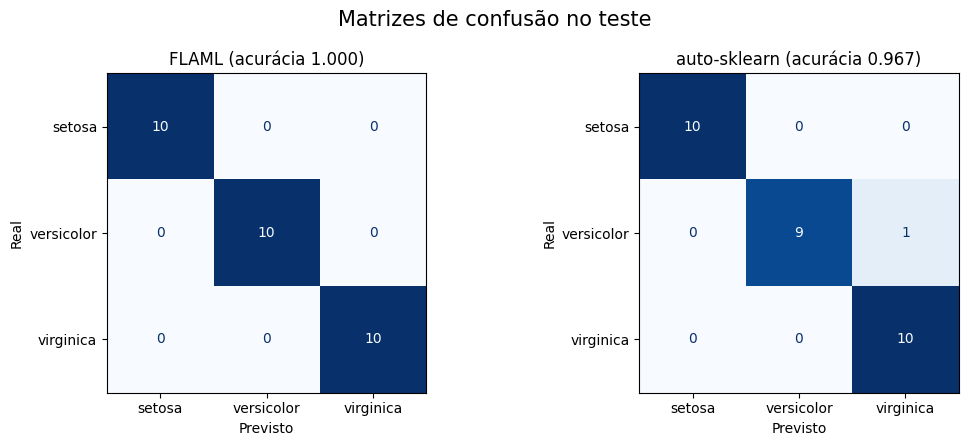

In [9]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.5))
for eixo, (nome, pred) in zip(eixos, previsoes.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=classes, ax=eixo, cmap="Blues", colorbar=False)
    eixo.set_title(f"{nome} (acurácia {acuracias[nome]:.3f})")
    eixo.set_xlabel("Previsto")
    eixo.set_ylabel("Real")
fig.suptitle("Matrizes de confusão no teste", fontsize=15)
plt.tight_layout()
plt.savefig("resultados/figuras/matrizes_confusao.png", dpi=120, bbox_inches="tight")
plt.show()

## 6. Comparação: desempenho, tempo e busca

A tabela junta os três pontos pedidos: acurácia no teste, tempo real de treino e quantos modelos cada ferramenta testou.

In [10]:
tabela = pd.DataFrame({
    "Ferramenta": ["FLAML", "auto-sklearn"],
    "Acurácia": [acuracias["FLAML"], acuracias["auto-sklearn"]],
    "Tempo de treino (s)": [tempo_flaml, tempo_askl],
    "Modelos testados": [testados_flaml, testados_askl],
    "Modelo final": [f"1 modelo ({modelo_flaml.best_estimator})", f"ensemble de {len(leaderboard)} modelo(s)"],
})
tabela.to_csv("resultados/comparacao.csv", index=False)
display(tabela.style.format({"Acurácia": "{:.3f}", "Tempo de treino (s)": "{:.1f}"}).hide(axis="index"))

Ferramenta,Acurácia,Tempo de treino (s),Modelos testados,Modelo final
FLAML,1.000,60.0,390,1 modelo (lrl1)
auto-sklearn,0.967,56.6,23,ensemble de 20 modelo(s)


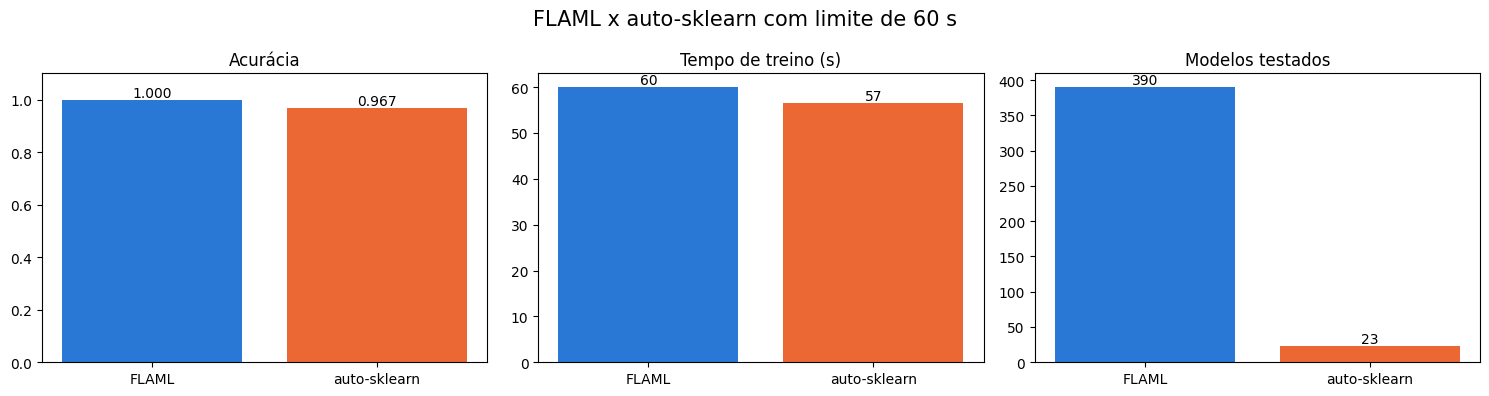

In [11]:
cores = ["#2a78d6", "#eb6834"]

fig, eixos = plt.subplots(1, 3, figsize=(15, 4))
for eixo, coluna in zip(eixos, ["Acurácia", "Tempo de treino (s)", "Modelos testados"]):
    barras = eixo.bar(tabela["Ferramenta"], tabela[coluna], color=cores)
    eixo.bar_label(barras, fmt="%.3f" if coluna == "Acurácia" else "%.0f")
    eixo.set_title(coluna)
eixos[0].set_ylim(0, 1.1)
fig.suptitle(f"FLAML x auto-sklearn com limite de {TEMPO} s", fontsize=15)
plt.tight_layout()
plt.savefig("resultados/figuras/comparacao.png", dpi=120, bbox_inches="tight")
plt.show()

## 7. Inspeção dos modelos escolhidos

O FLAML devolve **um único modelo**, com os hiperparâmetros à vista. O auto-sklearn devolve um **ensemble**:
vários modelos, cada um com um peso (`ensemble_weight`) na decisão final.

In [12]:
print("FLAML")
print("Algoritmo:", modelo_flaml.best_estimator)
print("Hiperparâmetros:", modelo_flaml.best_config)

print("\nauto-sklearn (modelos do ensemble)")
display(leaderboard)

FLAML
Algoritmo: lrl1
Hiperparâmetros: {'C': np.float64(1.0)}

auto-sklearn (modelos do ensemble)


,rank,ensemble_weight,type,cost,duration
model_id,,,,,
2,1,0.04,random_forest,0.025,1.856019
3,5,0.06,random_forest,0.025,2.534251
5,6,0.04,random_forest,0.025,1.594398
17,3,0.06,random_forest,0.025,1.661101
21,2,0.04,extra_trees,0.025,1.805661
23,4,0.06,extra_trees,0.025,2.044628
8,7,0.02,random_forest,0.050,1.672750
9,8,0.04,random_forest,0.050,3.129881
14,9,0.10,random_forest,0.050,1.650370


## 8. Relatório

O texto abaixo é montado com os números desta execução.

In [13]:
acc_flaml, acc_askl = acuracias["FLAML"], acuracias["auto-sklearn"]

if acc_flaml == acc_askl:
    resultado = f"houve empate: as duas ferramentas tiveram acurácia de {acc_flaml:.3f} no teste"
elif acc_flaml > acc_askl:
    resultado = f"o FLAML teve a melhor acurácia no teste ({acc_flaml:.3f} contra {acc_askl:.3f} do auto-sklearn)"
else:
    resultado = f"o auto-sklearn teve a melhor acurácia no teste ({acc_askl:.3f} contra {acc_flaml:.3f} do FLAML)"

desempenho = (f"**1. Desempenho.** Com a mesma divisão treino/teste e o mesmo limite de {TEMPO} s, {resultado}. "
              f"O teste tem só {len(y_test)} flores, então cada erro vale {100 / len(y_test):.1f} pontos percentuais: "
              f"uma diferença de 1 ou 2 acertos não basta para dizer que uma ferramenta é melhor que a outra. "
              f"As matrizes de confusão da seção 5 mostram em quais espécies cada modelo errou.")

custo = (f"**2. Custo computacional.** O treino levou {tempo_flaml:.1f} s no FLAML e {tempo_askl:.1f} s no auto-sklearn. "
         f"Nesse tempo, o FLAML testou {testados_flaml} configurações e o auto-sklearn testou {testados_askl} pipelines. "
         f"O FLAML começa pelos modelos mais baratos e roda tudo no mesmo processo. O auto-sklearn roda cada pipeline em um "
         f"processo separado, com limite de tempo e de memória, e ainda monta um ensemble no final; o resumo que ele imprime "
         f"na seção 4 mostra quantas execuções deram certo, falharam ou passaram desses limites. Além disso, o auto-sklearn "
         f"não instala no Python atual do Colab e precisou de um ambiente separado com Python 3.9, o que deixou a instalação "
         f"bem mais demorada que a do FLAML.")

inspecao = (f"**3. Interpretabilidade / Pipelines.** O FLAML foi o mais fácil de inspecionar: ele devolve um único modelo "
            f"(`{modelo_flaml.best_estimator}`) e os hiperparâmetros ficam em `best_config`. O auto-sklearn devolve um ensemble "
            f"de {len(leaderboard)} modelo(s), cada um com seu peso e seu pré-processamento. O `leaderboard()` ajuda a ver "
            f"esses modelos, mas entender a decisão final exige olhar vários deles ao mesmo tempo.")

display(Markdown(f"{desempenho}\n\n{custo}\n\n{inspecao}"))

**1. Desempenho.** Com a mesma divisão treino/teste e o mesmo limite de 60 s, o FLAML teve a melhor acurácia no teste (1.000 contra 0.967 do auto-sklearn). O teste tem só 30 flores, então cada erro vale 3.3 pontos percentuais: uma diferença de 1 ou 2 acertos não basta para dizer que uma ferramenta é melhor que a outra. As matrizes de confusão da seção 5 mostram em quais espécies cada modelo errou.

**2. Custo computacional.** O treino levou 60.0 s no FLAML e 56.6 s no auto-sklearn. Nesse tempo, o FLAML testou 390 configurações e o auto-sklearn testou 23 pipelines. O FLAML começa pelos modelos mais baratos e roda tudo no mesmo processo. O auto-sklearn roda cada pipeline em um processo separado, com limite de tempo e de memória, e ainda monta um ensemble no final; o resumo que ele imprime na seção 4 mostra quantas execuções deram certo, falharam ou passaram desses limites. Além disso, o auto-sklearn não instala no Python atual do Colab e precisou de um ambiente separado com Python 3.9, o que deixou a instalação bem mais demorada que a do FLAML.

**3. Interpretabilidade / Pipelines.** O FLAML foi o mais fácil de inspecionar: ele devolve um único modelo (`lrl1`) e os hiperparâmetros ficam em `best_config`. O auto-sklearn devolve um ensemble de 20 modelo(s), cada um com seu peso e seu pré-processamento. O `leaderboard()` ajuda a ver esses modelos, mas entender a decisão final exige olhar vários deles ao mesmo tempo.